# Abstention and review queues

**Recipe 38** · Level 3 (Intermediate) · Decision type: `Choice`

Route uncertain ticket classifications to review using thresholds selected from validation examples and measure accuracy versus coverage on a held-out set.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)

## What you will build

A support ticket router with an explicit option to abstain. Jev reads one ticket and names exactly one of four queues: `self_serve`, `tier1_support`, `tier2_engineering`, or `insufficient_information` (this use case's named fallback, for a ticket that does not resolve to one queue). Python then decides, from the answer's own confidence, whether to act on that choice automatically or send the ticket to a simulated review queue instead. The one setting this decision needs — how confident is confident enough — is chosen once on `validation` examples and frozen; by the end you will have seen that choice made, applied once to `test`, and reported two ways: as a plain classification accuracy that ignores abstention, and as the coverage, accuracy and risk of the composed decision that a reader actually experiences.

## Setup and run mode

The notebook runs from its own folder with the standard library and `jev_cookbook` only. `get_backend(fixtures=...)` replays stored answers offline; setting `JEV_COOKBOOK_LIVE=1` (see the README) swaps in live calls with the same question definitions and changes nothing else. The header states which mode ran, and every reported metric below carries that mode with it. The individual answers and per-example lines shown along the way are not reported metrics, so they may carry no label of their own; they come from the mode the header names.

In [1]:
from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import (
    accuracy,
    evaluate_outcomes,
    evaluate_selective,
    select_confidence_threshold,
    selective_curve,
)
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.simulation import ActionLog, ReviewQueue
from jev_cookbook.style import (
    apply_style,
    plot_answer_probabilities,
    plot_risk_coverage,
    run_header,
    show_answer,
)

apply_style()
helpers = load_helpers()  # this recipe's helpers.py, loaded by path
examples = load_inputs()
labels = load_labels()
backend = get_backend(fixtures=responses_path())
# scored excludes the two demo examples: they carry no gold label, so no metric below
# is about them (see "gold label" under Evaluation).
scored = [e for e in examples if e.split not in ("train", "demo")]

offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
# CONTRIBUTING.md section 2: a number from the validation split is a selection step,
# not a result. This label does not depend on the run mode, unlike check above: even a
# recorded or live run must not print a bare validation number.
selection = " (a selection step, not a reported result)"

run_header(
    38,
    "Abstention and review queues",
    backend=backend,
    n_examples=len(scored),
)

Recipe 38: Abstention and review queues
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 40 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

The state is everything Jev sees, and Python builds it. Each ticket in `fixtures/inputs.jsonl` carries `fields`: a ticket reference, a subject and a description. `build_state` passes on the subject and the description only; the reference stays in Python and is attached to every outcome below, so an identifier never passes through the model and every result still traces back to its ticket.

In [2]:
import json

demo = {e.id: e for e in examples if e.split == "demo"}
ticket = demo["d01-ambiguous-ss-tier1"]
print("Python has:")
print(json.dumps(ticket.fields, indent=2))
state = helpers.build_state(ticket.fields)
print("Jev sees:")
print(json.dumps(state, indent=2))

Python has:
{
  "ticket_id": "TKT-5001",
  "subject": "Can't sign back in after changing email",
  "description": "I changed my email provider and now the password reset link goes to an inbox I can no longer open."
}
Jev sees:
{
  "subject": "Can't sign back in after changing email",
  "description": "I changed my email provider and now the password reset link goes to an inbox I can no longer open."
}


## The questions

There is one question, and it asks one thing: which queue should this ticket be routed to? A `Choice` fits because the queues are exclusive and Jev should commit to one. Python builds the option list from the three queues it is willing to route to automatically, plus the explicit fallback this use case names, `insufficient_information`, for a ticket that does not resolve to one queue (CONTRIBUTING.md section 3: "Include none, other, no_match, or uncertain outcomes when the use case calls for them."). The two pairs of options that are easiest to confuse each say, in their own description, what belongs to the neighbouring option instead, so the question itself carries the distinction a reader would otherwise have to guess at.

In [3]:
questions = helpers.build_questions()
queue = questions["queue"]
print(queue.instructions)
for name, description in queue.criteria.items():
    print(f"  {name}:")
    print(f"    {description}")

Which support queue should this ticket be routed to?
  self_serve:
    The request is a common how-to question the help center already answers without any account-specific investigation: resetting a password while still signed in, how a billing cycle or a trial works, where a feature lives. A request that needs a human to verify identity, change something only support can reach, or look into this specific account belongs to tier1_support instead.
  tier1_support:
    The request needs a support agent to look at or change something specific to this account: verifying identity to recover access, adjusting a subscription or refund, granting a teammate access, or resending a document support alone can issue. A report that the product is failing to work as built belongs to tier2_engineering instead, even if a human still has to look at the account to confirm it.
  tier2_engineering:
    The request reports the product failing to behave as it was built to: an error, a crash, a page or export

## One answer up close

Before any aggregate, look at one typed answer. A `Choice` answer holds the chosen option, a `probabilities` value for every option, and a `confidence`: the top probability rescaled by the number of options, `(p_max - 1/n) / (1 - 1/n)`, so it is 0 when the top option has no more than an even share and 1 when one option holds all the probability. This ticket is the ambiguous `self_serve`/`tier1_support` case shown above: the recovery email is also gone, so there is no self-serve path back in, and the answer's own probabilities show the model weighing both queues rather than picking one outright.

In [4]:
result = backend.decide(state, questions)
answer = result["queue"]
show_answer(answer)

Choice: tier1_support (confidence 0.25)
  tier1_support             0.44  #########
  self_serve                0.40  ########
  tier2_engineering         0.09  ##
  insufficient_information  0.07  #
Provenance: synthetic


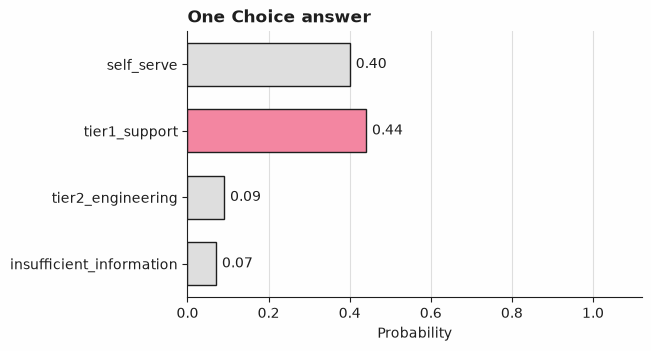

In [5]:
plot_answer_probabilities(answer, title="One Choice answer")

## Python's part

Jev supplies the judgment; the rule that acts on it is code, in `helpers.route_ticket`. It has two branches, and only one of them is a [confidence gate](../../docs/glossary.md#confidence-gate) — a cut-off applied to an answer's own confidence that decides whether to trust it enough to act on automatically or send it to [review](../../docs/glossary.md#review) instead. `insufficient_information` is never routed automatically, whatever its confidence: the option itself already says the ticket does not resolve to one queue, so it is sent to review unconditionally rather than run past a gate meant for a queue it will never enter. This passes every part of CONTRIBUTING.md section 4's three-part test on its own (it is a complete answer, not a deferral; nothing is recorded as an action; being wrong leaves nothing standing beyond the missed ticket itself), but this rule still sends it to review like every other unconfident or unrecognized case rather than claim that exemption — the test names when the exemption is *available*, not when it is required, and gating a qualifying fallback anyway is compliant too.

The confidence gate's threshold is chosen here, on `validation`, and frozen for the rest of this notebook. Only an answer that names one of the three real queues (`helpers.REAL_QUEUES`) can ever be routed automatically, so only those answers may set the bar — an `insufficient_information` answer is excluded from the selection the same way it is excluded from automatic routing. `select_confidence_threshold` is given `min_coverage=0.75` rather than `target_accuracy=1.0`, though on this pool the two happen to coincide: `target_accuracy=1.0` is feasible here and selects the identical threshold, `0.7067`, because that already is the lowest threshold whose answered subset of validation's queue-naming answers scores perfect accuracy. `min_coverage` is the one used here regardless, because it states the floor in terms a reader sets directly — how much of the pool must be answered — rather than in terms of whatever accuracy a given validation pool happens to allow; a pool with no threshold reaching perfect accuracy would make `target_accuracy=1.0` fail outright, while `min_coverage=0.75` only ever asks for enough coverage, never for a specific accuracy. That the two objectives land on the same threshold here is a fact about this pool, not a guarantee `select_confidence_threshold` makes in general.

In [6]:
val_examples = select_split(examples, "validation")
val_answers = [
    backend.decide(helpers.build_state(e.fields), questions)["queue"] for e in val_examples
]
val_gold = [labels[e.id] for e in val_examples]
# Only an answer that names a real queue can be routed automatically, so only those
# answers may set the bar.
named = [
    (a.choice == g, a.confidence)
    for a, g in zip(val_answers, val_gold, strict=True)
    if a.choice in helpers.REAL_QUEUES
]
min_coverage = 0.75
print(
    f"objective: select_confidence_threshold(..., min_coverage={min_coverage:.2f})"
    f"{selection}{check}"
)
threshold = select_confidence_threshold(
    [ok for ok, _ in named], [c for _, c in named], min_coverage=min_coverage
)
print(
    f"validation answers naming a real queue: {len(named)} of {len(val_answers)}{selection}{check}"
)
print(f"chosen threshold, frozen from here on: {threshold:.4f}{selection}{check}")

second = demo["d02-insufficient-vague"]
second_answer = backend.decide(helpers.build_state(second.fields), questions)["queue"]
# The first demo's answer is the one shown above, so it is not requested a second time.
for example, shown in ((ticket, answer), (second, second_answer)):
    routing = helpers.route_ticket(example.fields["ticket_id"], shown, threshold)
    print(
        f"{routing.ticket_id}: {shown.choice} at confidence {shown.confidence:.4f} "
        f"-> {routing.outcome} ({routing.reason})"
    )

objective: select_confidence_threshold(..., min_coverage=0.75) (a selection step, not a reported result) (a pipeline check, not a Jev result)
validation answers naming a real queue: 17 of 20 (a selection step, not a reported result) (a pipeline check, not a Jev result)
chosen threshold, frozen from here on: 0.7067 (a selection step, not a reported result) (a pipeline check, not a Jev result)
TKT-5001: tier1_support at confidence 0.2533 -> review (confidence below the threshold)
TKT-5002: insufficient_information at confidence 0.2267 -> review (not enough information to classify)


## Evaluation

The threshold was chosen and frozen above, on `validation`. This section reports what the frozen rule does on `test`, two ways. The **per-question** view is the plain classification accuracy of the raw `Choice` answer against each ticket's [gold label](../../docs/glossary.md#gold-label) (the example's recorded correct answer, from `fixtures/labels.jsonl`, used only to score an answer after the fact and never shown to Jev): it says nothing about which tickets were actually handed to a person. The **task-level** view is `route_ticket` applied to every test ticket, scored with `jev_cookbook.evaluation.evaluate_outcomes`: [coverage](../../docs/glossary.md#coverage) (the share of tickets routed automatically rather than sent to review), accuracy restricted to that answered subset, and [risk](../../docs/glossary.md#risk) (the error rate among tickets routed automatically, `1 - accuracy`). This is [selective prediction](../../docs/glossary.md#selective-prediction): trading coverage for lower risk by abstaining on anything the confidence gate does not clear, with an abstention never scored as an error. `evaluate_outcomes` is the right tool here rather than `evaluate_selective`, because `route_ticket` has a second, unconditional review branch beyond the confidence gate (`insufficient_information`) — a plain confidence-only view can disagree with the rule about which tickets were actually answered, shown directly below. `test` is used once, to report; `validation` never is, and every number drawn from it below carries both a selection-step label and the offline pipeline-check label.

In [7]:
val_correct = [a.choice == g for a, g in zip(val_answers, val_gold, strict=True)]
print(f"validation, {len(val_examples)} examples{selection}{check}")
print(
    f"per-question accuracy of the raw choice on validation: "
    f"{accuracy(val_gold, val_answers):.4f}{selection}{check}"
)

validation, 20 examples (a selection step, not a reported result) (a pipeline check, not a Jev result)
per-question accuracy of the raw choice on validation: 0.9500 (a selection step, not a reported result) (a pipeline check, not a Jev result)


In [8]:
test_examples = select_split(examples, "test")
test_answers = [
    backend.decide(helpers.build_state(e.fields), questions)["queue"] for e in test_examples
]
test_gold = [labels[e.id] for e in test_examples]
test_correct = [a.choice == g for a, g in zip(test_answers, test_gold, strict=True)]
test_confidence = [a.confidence for a in test_answers]

routings = [
    helpers.route_ticket(e.fields["ticket_id"], a, threshold)
    for e, a in zip(test_examples, test_answers, strict=True)
]
accepted = [r.outcome == helpers.ANSWERED for r in routings]

print(f"test, {len(test_examples)} examples, threshold {threshold:.4f} frozen{check}")
print(
    f"per-question accuracy of the raw choice (ignores review): "
    f"{accuracy(test_gold, test_answers):.4f}{check}"
)

task = evaluate_outcomes(accepted, test_correct)
print(
    f"task-level, whole test split (N={task.n_total}): coverage {task.coverage:.4f}, "
    f"accuracy {task.accuracy:.4f}, risk {task.risk:.4f}{check}"
)

# The confidence-only view, restricted to answers that could ever clear the gate (the
# same "named" filter the threshold was chosen from): the narrower denominator a
# confidence gate alone could actually apply to.
named_mask = [a.choice in helpers.REAL_QUEUES for a in test_answers]
named_correct = [c for c, keep in zip(test_correct, named_mask, strict=True) if keep]
named_confidence = [c for c, keep in zip(test_confidence, named_mask, strict=True) if keep]
gate_only = evaluate_selective(named_correct, named_confidence, threshold)
print(
    f"confidence-only view, queue-naming answers only (N={gate_only.n_total}): "
    f"coverage {gate_only.coverage:.4f}, accuracy {gate_only.accuracy:.4f}, "
    f"risk {gate_only.risk:.4f}{check}"
)

# A naive confidence-only view applied to the WHOLE split -- blind to the rule's own
# unconditional review branch -- disagrees with the rule about which tickets were
# answered.
naive = evaluate_selective(test_correct, test_confidence, threshold)
disagreements = [
    e.id
    for e, acc, conf in zip(test_examples, accepted, test_confidence, strict=True)
    if acc != (conf >= threshold)
]
print(
    f"naive confidence-only view, whole split (N={naive.n_total}): "
    f"coverage {naive.coverage:.4f}, accuracy {naive.accuracy:.4f}, "
    f"risk {naive.risk:.4f}{check}"
)
print(f"tickets the naive view and the rule disagree about: {disagreements}{check}")

test, 20 examples, threshold 0.7067 frozen (a pipeline check, not a Jev result)
per-question accuracy of the raw choice (ignores review): 0.9000 (a pipeline check, not a Jev result)
task-level, whole test split (N=20): coverage 0.6500, accuracy 0.9231, risk 0.0769 (a pipeline check, not a Jev result)
confidence-only view, queue-naming answers only (N=17): coverage 0.7647, accuracy 0.9231, risk 0.0769 (a pipeline check, not a Jev result)
naive confidence-only view, whole split (N=20): coverage 0.7000, accuracy 0.9286, risk 0.0714 (a pipeline check, not a Jev result)
tickets the naive view and the rule disagree about: ['t12-insufficient-offtopic'] (a pipeline check, not a Jev result)


### The full risk-coverage curve

The single frozen point above is one place to stand on a curve: sweeping the confidence gate across every observed `test` confidence shows the whole tradeoff, not just the operating point this notebook chose. The curve below is swept over the same queue-naming subset the threshold itself was chosen from, since `insufficient_information` answers are never candidates for automatic routing at any threshold.

risk-coverage sweep over 17 queue-naming test answers (a pipeline check, not a Jev result):
  gate >= 0.8400: coverage 0.0588, accuracy 1.0000, risk 0.0000 (a pipeline check, not a Jev result)
  gate >= 0.8267: coverage 0.1176, accuracy 1.0000, risk 0.0000 (a pipeline check, not a Jev result)
  gate >= 0.8133: coverage 0.1765, accuracy 1.0000, risk 0.0000 (a pipeline check, not a Jev result)
  gate >= 0.8000: coverage 0.2941, accuracy 1.0000, risk 0.0000 (a pipeline check, not a Jev result)
  gate >= 0.7867: coverage 0.4118, accuracy 1.0000, risk 0.0000 (a pipeline check, not a Jev result)
  gate >= 0.7733: coverage 0.4706, accuracy 1.0000, risk 0.0000 (a pipeline check, not a Jev result)
  gate >= 0.7600: coverage 0.6471, accuracy 0.9091, risk 0.0909 (a pipeline check, not a Jev result)
  gate >= 0.7467: coverage 0.7059, accuracy 0.9167, risk 0.0833 (a pipeline check, not a Jev result)
  gate >= 0.7200: coverage 0.7647, accuracy 0.9231, risk 0.0769 (a pipeline check, not a Jev result)

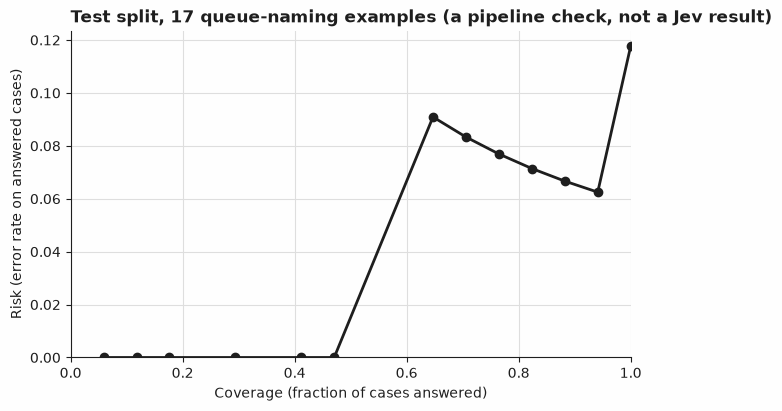

In [9]:
curve = selective_curve(named_correct, named_confidence)
print(f"risk-coverage sweep over {len(named_correct)} queue-naming test answers{check}:")
for t, cov, acc, risk in zip(
    curve.thresholds, curve.coverage, curve.accuracy, curve.risk, strict=True
):
    print(f"  gate >= {t:.4f}: coverage {cov:.4f}, accuracy {acc:.4f}, risk {risk:.4f}{check}")
plot_risk_coverage(curve, title=f"Test split, {len(named_correct)} queue-naming examples{check}")

### The simulated queues

Nothing here sends a message or changes a ticket. Every automatic routing is recorded in a simulated `ActionLog`, and every ticket sent to review lands in a simulated `ReviewQueue` with the reason attached, so a reader can see exactly what Python did with each answer without anything leaving this notebook.

In [10]:
action_log = ActionLog()
review_queue = ReviewQueue()
for _example, a, routing in zip(test_examples, test_answers, routings, strict=True):
    if routing.outcome == helpers.ANSWERED:
        action_log.record(
            "route_to_queue",
            {"ticket_id": routing.ticket_id, "queue": routing.label},
            answer=a,
            rule=routing.reason,
        )
    else:
        review_queue.submit(
            {"ticket_id": routing.ticket_id, "label": routing.label},
            routing.reason,
            answer=a,
        )
print(f"routed automatically (ActionLog entries): {len(action_log.to_dicts())}{check}")
print(f"sent to review (ReviewQueue entries): {len(review_queue.pending())}{check}")
reasons = {}
for item in review_queue.pending():
    reasons[item.reason] = reasons.get(item.reason, 0) + 1
for reason, n in sorted(reasons.items()):
    print(f"  review because {reason!r}: {n}{check}")

routed automatically (ActionLog entries): 13 (a pipeline check, not a Jev result)
sent to review (ReviewQueue entries): 7 (a pipeline check, not a Jev result)
  review because 'confidence below the threshold': 4 (a pipeline check, not a Jev result)
  review because 'not enough information to classify': 3 (a pipeline check, not a Jev result)


In [11]:
print("Test tickets the raw choice got wrong, and what Python did with them:")
for example, a, g, routing in zip(test_examples, test_answers, test_gold, routings, strict=True):
    if a.choice != g:
        print(
            f"  {example.id}: gold {g}, answered {a.choice} "
            f"(confidence {a.confidence:.4f}) -> {routing.outcome}"
        )

Test tickets the raw choice got wrong, and what Python did with them:
  t08-ambiguous-tier1-tier2: gold tier2_engineering, answered tier1_support (confidence 0.7600) -> answered
  t16-ss-trial-length-lowconf-wrong: gold self_serve, answered tier1_support (confidence 0.0267) -> review


The cell above is why `route_ticket` is not the same thing as the plain classification accuracy: `t08-ambiguous-tier1-tier2` is wrong *and* confident, so the gate lets it through, and that single mistake is where the task-level risk above comes from. `t16-ss-trial-length-lowconf-wrong` is wrong too, but at low confidence, so the gate catches it and sends it to review instead — a mistake that never reaches the automatic-routing accuracy at all. A per-question accuracy cannot tell these two mistakes apart; only the coverage, accuracy and risk of the composed decision can.

The disagreement reported earlier in this section ("tickets the naive view and the rule disagree about") shows the other half of the same lesson: `t12-insufficient-offtopic` is a confident `insufficient_information` answer, so a view that only ever checks "is the confidence above the gate" would count it as routed automatically — it is not, because `insufficient_information` is never a candidate for automatic routing at all. An argmax-against-gold metric such as the per-question accuracy, or a confidence-only view applied blind to this second branch, is structurally unable to see that gap: it can only ask whether the named choice was right, never whether the rule actually acted on it. That is exactly why coverage, not accuracy or risk, is where this recipe's abstention rule shows up.

## What was and was not measured

What this run can say about Jev depends on its mode, which the cell below states from `backend.mode`: a synthetic or scripted run is a pipeline check only, on the fixture sample it ran against; a recorded or live run states the model the API returned and when, for exactly the examples it covers. Nothing here says anything about Jev's quality, speed or cost unless that cell reports a recorded or live run. `N` below counts only the examples that carry a gold label, so it excludes the two `demo` tickets shown earlier.

In [12]:
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test examples{check}")
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ()) or "this run"
    print(f"Provenance: {backend.mode}, model {backend.model}")
    print(f"Captured: {dates}")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test examples")

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 20 validation and 20 test examples (a pipeline check, not a Jev result)


## Next steps

- Raise `min_coverage` in the threshold selection above and re-run from the "Python's part" section down: a tighter coverage requirement can only move the frozen threshold down or leave it unchanged, never up, since asking for more coverage only ever admits lower-confidence thresholds into the feasible set — the opposite of lowering it, which can only raise the threshold or leave it unchanged. On this pool `min_coverage=0.75` already lands on `0.7067`, the lowest threshold whose answered subset is still perfectly accurate on validation (the full curve above already shows what every other cut-off would have cost or bought), so lowering the requirement cannot do better and leaves the frozen threshold exactly where it is. Raise it to `0.85`, say, and watch the frozen threshold drop, moving every task-level figure below with it.
- Add a ticket to `ROWS` in `build_fixtures.py` that is wrong and confident at a level just above the frozen threshold, run `python build_fixtures.py --force`, and watch the task-level risk move.
- Neighbouring recipes: [`04-support-ticket-routing`](../04-support-ticket-routing/) (`Choice`), which this recipe builds on and whose categories this one's queues deliberately differ from, and [`19-ci-failure-classification`](../19-ci-failure-classification/) (`Choice`), another recipe that routes an uncertain or unrecognized answer to a person rather than act on it automatically.

A neighbour link above is a folder link, `../NN-slug/`, and that is the convention: `tools/render_catalog.py` builds the root README's catalog table from bare recipe titles with no per-row anchor, so a recipe cannot reliably link to another recipe's row there instead. Link only a neighbour whose `notebook.ipynb` is already committed on `main`: a folder link to one that is not yet published would 404 on GitHub, and a forward link like that is not allowed.